## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay)
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 2. Load Iris Dataset

In [2]:
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = pd.Categorical.from_codes(iris.target, iris.target_names)
display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Exploratory Data Analysis (EDA)

### 3.1 Dataset Shape

In [3]:
print("Dataset shape (rows, columns):", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset shape (rows, columns): (150, 5)
Number of rows: 150
Number of columns: 5


### 3.2 Data Types

In [4]:
print(df.dtypes)

sepal length (cm)     float64
sepal width (cm)      float64
petal length (cm)     float64
petal width (cm)      float64
species              category
dtype: object


### 3.3 Null Values Check

In [5]:
print(df.isnull().sum())
print("Total missing values:", df.isnull().sum().sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64
Total missing values: 0


### 3.4 Descriptive Statistics

In [6]:
display(df.describe())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


### 3.5 Species Distribution

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


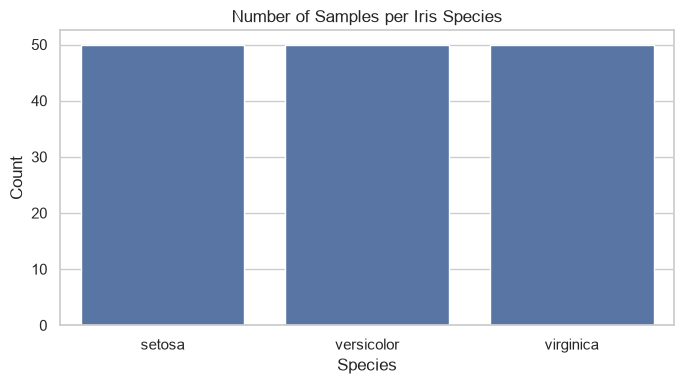

In [7]:
print(df["species"].value_counts())

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="species")
plt.title("Number of Samples per Iris Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## 4. Data Visualisation

### 4.1 Pairplot

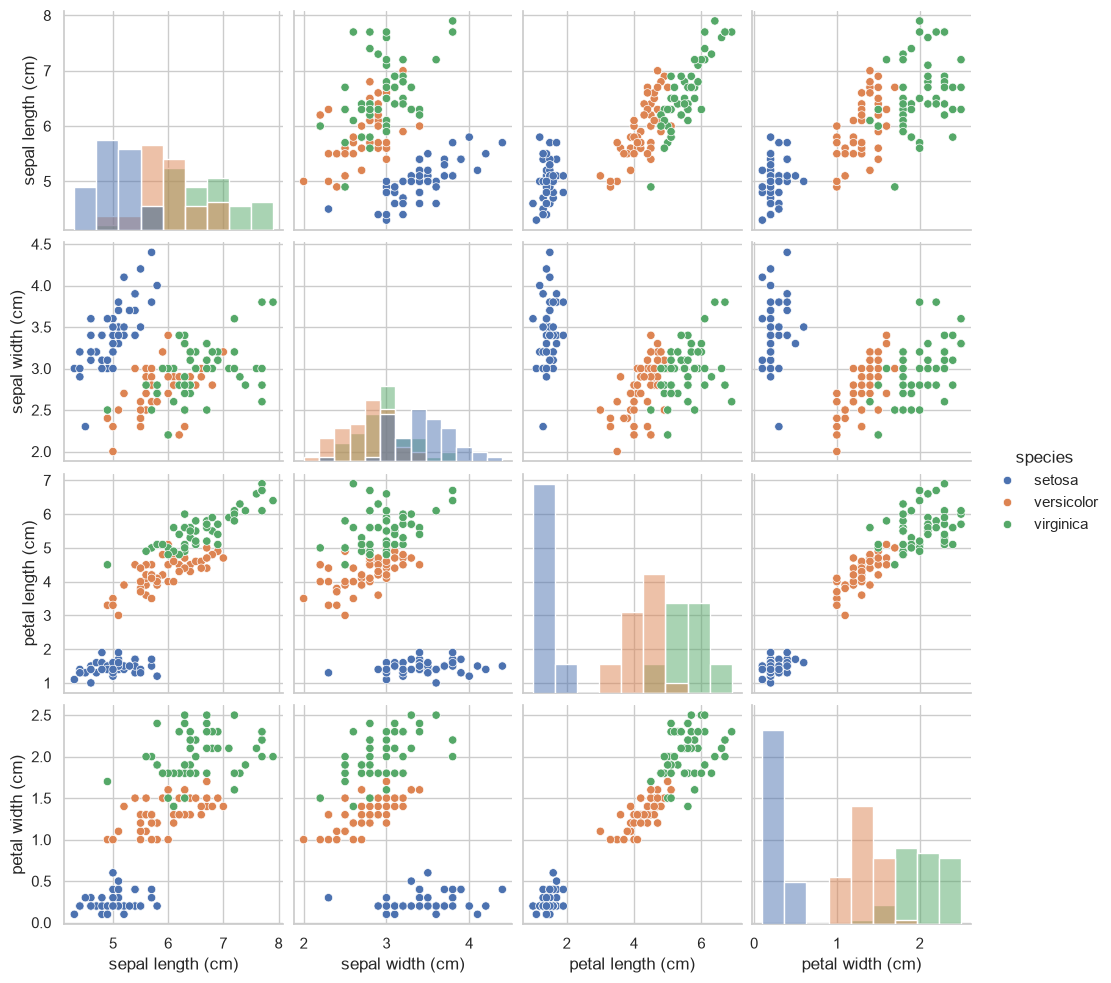

In [8]:
sns.pairplot(df, hue="species", diag_kind="hist")
plt.show()

### 4.2 Boxplots for Each Feature

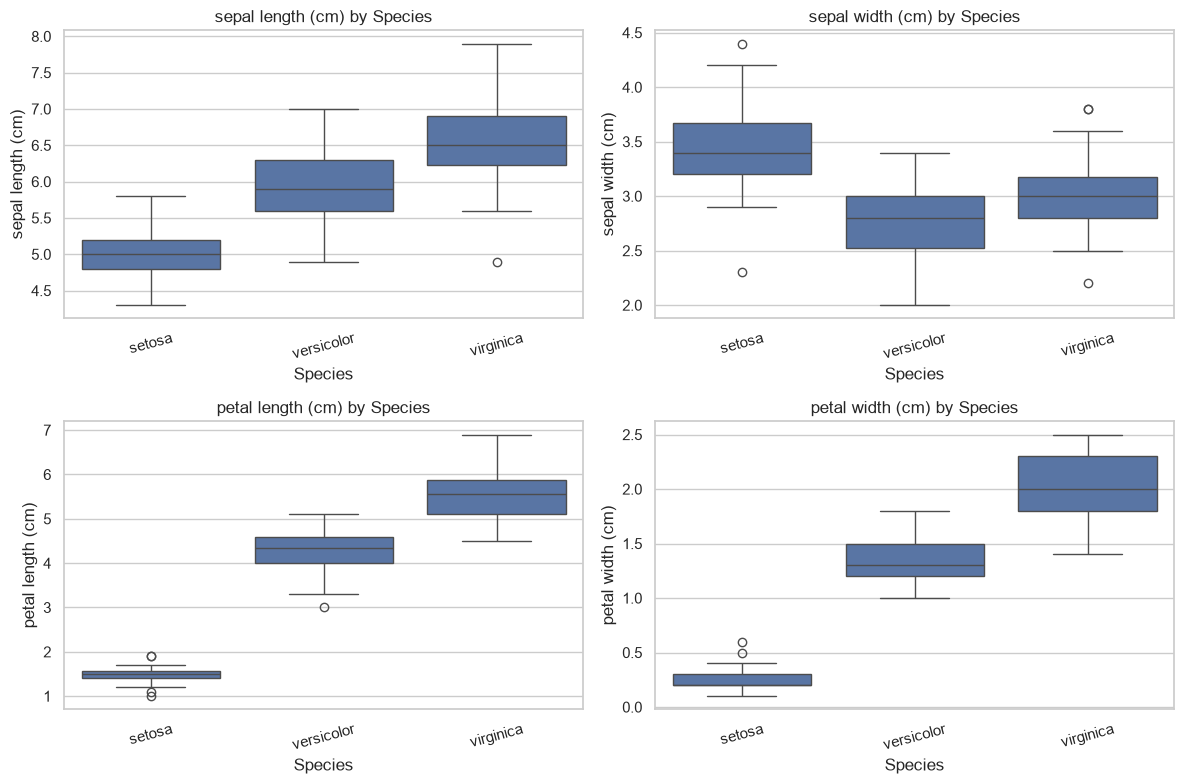

In [9]:
feature_columns = iris.feature_names
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, feature in zip(axes, feature_columns):
    sns.boxplot(data=df, x="species", y=feature, ax=ax)
    ax.set_title(f"{feature} by Species")
    ax.set_xlabel("Species")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## 5. Prepare Features and Target

In [10]:
X = df[feature_columns]
y = df["species"]
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (150, 4)
Target shape: (150,)


## 6. Train/Test Split (80/20)

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 120
Testing samples: 30


## 7. Train Two Classification Models

### 7.1 Logistic Regression
StandardScaler is included in a pipeline because Logistic Regression is sensitive to feature scale.

In [12]:
logistic_model = Pipeline([("scaler", StandardScaler()), ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
logistic_model.fit(X_train, y_train)
print("Logistic Regression training complete.")

Logistic Regression training complete.


### 7.2 Random Forest

In [13]:
random_forest_model = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
random_forest_model.fit(X_train, y_train)
print("Random Forest training complete.")

Random Forest training complete.


## 8. Model Evaluation


Logistic Regression
Accuracy: 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



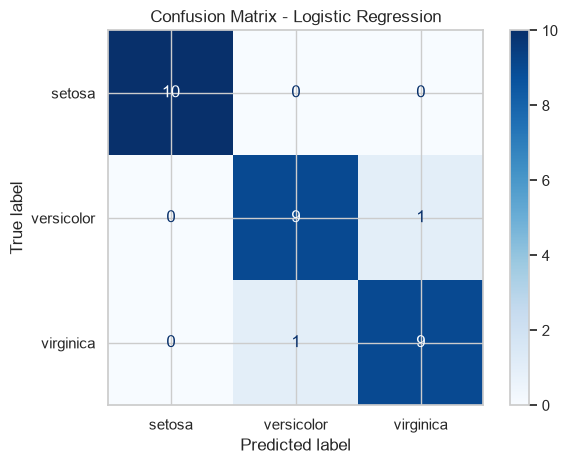


Random Forest
Accuracy: 0.9000

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



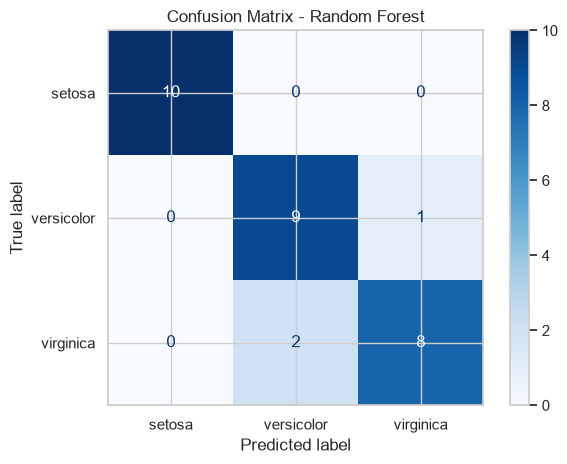

,Model,Accuracy,Macro F1-score
0,Logistic Regression,0.933333,0.933333
1,Random Forest,0.900000,0.899749


In [14]:
models = {"Logistic Regression": logistic_model, "Random Forest": random_forest_model}
results = []
class_labels = list(iris.target_names)

for model_name, model in models.items():
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    macro_f1 = report["macro avg"]["f1-score"]
    results.append({"Model": model_name, "Accuracy": accuracy, "Macro F1-score": macro_f1})

    print(f"\n{'=' * 55}\n{model_name}\n{'=' * 55}")
    print(f"Accuracy: {accuracy:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    cm = confusion_matrix(y_test, y_pred, labels=class_labels)
    display_plot = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
    display_plot.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()

results_df = pd.DataFrame(results).sort_values(by=["Accuracy", "Macro F1-score"], ascending=False)
display(results_df)

## 9. Best Model Selection and Justification

In [15]:
best_model_name = results_df.iloc[0]["Model"]
best_accuracy = results_df.iloc[0]["Accuracy"]
best_macro_f1 = results_df.iloc[0]["Macro F1-score"]
print("Best-performing model:", best_model_name)
print(f"Test accuracy: {best_accuracy:.4f}")
print(f"Macro F1-score: {best_macro_f1:.4f}")

Best-performing model: Logistic Regression
Test accuracy: 0.9333
Macro F1-score: 0.9333


## 10. Predict a New Flower

In [16]:
sample = pd.DataFrame([[5.1, 3.5, 1.4, 0.2]], columns=feature_columns)
best_model = models[best_model_name]
predicted_species = best_model.predict(sample)[0]
display(sample)
print("Predicted Iris species:", predicted_species)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2


Predicted Iris species: setosa
